![Imgur](https://i.imgur.com/h4PPC71.png)
#**19-modul. Unsupervised learning. Clustering**
# 19.8. Modul boʻyicha yakuniy amaliy vazifa. Mijozlarni xarajat turlariga qarab segmentlash

**Ushbu vazifa orqali siz:**

✔️ klasterlash;

✔️ maʼlumotlarni normallashtirish;

✔️ klaster tahlili;

✔️ vizualizatsiya kabi real data sayns loyihalari uchun zarur texnik ko‘nikmalarga ega bo‘lasiz.

## **Dataset: Wholesale Customers Data**  
- **Manba:** [UCI Machine Learning Repository](https://archive.ics.uci.edu/ml/datasets/wholesale+customers)  
- **Hajmi:** **22 KB**
- **Format:** CSV  
- **Tavsif:** bu dataset **ulgurji savdo mijozlarini** xarajatlar bo‘yicha klasterlash uchun ishlatiladi.  
  U quyidagi xarajat kategoriyalarini o‘z ichiga oladi:  
  - **channel** (mijoz turi: 1 – HoReCa (mehmonxona, restoran, kafelar) yoki 2 – chakana savdo)  
  - **region** (hudud: 1 – Lisbon, 2 – Oporto, 3 – boshqa)  
  - **fresh** (yangi mahsulotlarga sarf qilingan summa)  
  - **milk** (sut mahsulotlariga sarf qilingan summa)  
  - **grocery** (oziq-ovqat mahsulotlariga sarf qilingan summa)  
  - **frozen** (muzlatilgan mahsulotlarga sarf qilingan summa)  
  - **Detergents_Paper** (kimyoviy tozalash va qog‘oz mahsulotlari)  
  - **delicassen** (delikates mahsulotlar)  

---

### **Vazifa: mijozlarni xarajat turlariga qarab segmentlash**  
Maqsad – **mijozlarni xarajat qiladigan mahsulotlar bo‘yicha klasterlash va marketologlarga tavsiyalar berish**  

---

### **Klasterlash bosqichlari**  
1) **Maʼlumotlarni tayyorlash**  
   - `Channel` va `Region` ustunlarini olib tashlang yoki kodlang.  
   - Har bir xarajat ustunini **normalizatsiya qiling**.  

2) **K-means klasterlashni amalga oshirish**  
   - K-means yordamida mijozlarni **xarajat qilish odatlari** bo‘yicha segmentlarga ajrating.  

3) **Natijalarni vizualizatsiya qilish**  
   - **Pairplot yoki scatter plot** yordamida klasterlarni ko‘rsating.  
   - Har bir segmentning xarajatlar bo‘yicha o‘rtacha qiymatini diagrammada aks ettiring.

---

###*** ESLATMA**: *Ushbu amaliy vazifada siz oʻtmagan mavzulardan ham savollar va vazifalar boʻlishi mumkin! Bu savollarni mustaqil oʻrganishingiz kerak boʻladi. Bunday vazifalar mustaqil izlanish koʻnikmangizni oshirish uchun tayyorlandi!*

In [ ]:
import pandas as pd
df = pd.read_csv("https://raw.githubusercontent.com/alishermutalov/praktikum-datasets/refs/heads/praktikum/Wholesale_customers_data.csv")
df.head()


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


{'Fresh': 2.6, 'Milk': 4.1, 'Grocery': 3.6, 'Frozen': 5.9, 'Detergents_Paper': 3.6, 'Delicassen': 11.2}


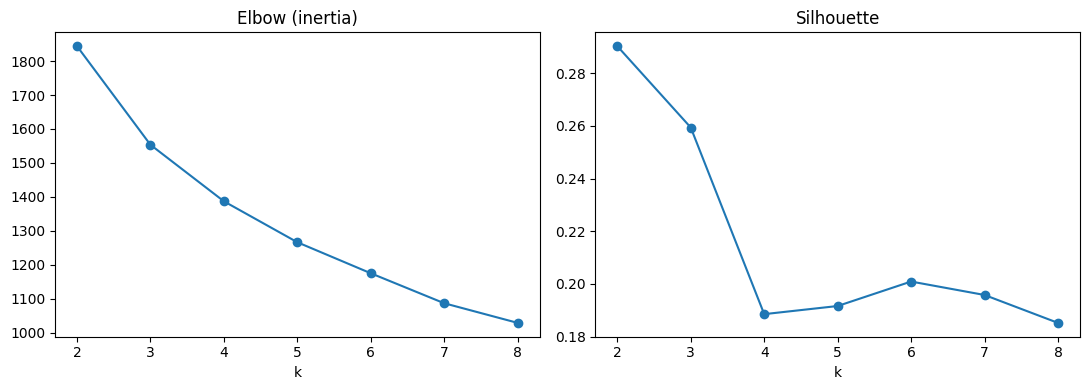

Cluster
0     80
1    147
2    213
Name: count, dtype: int64


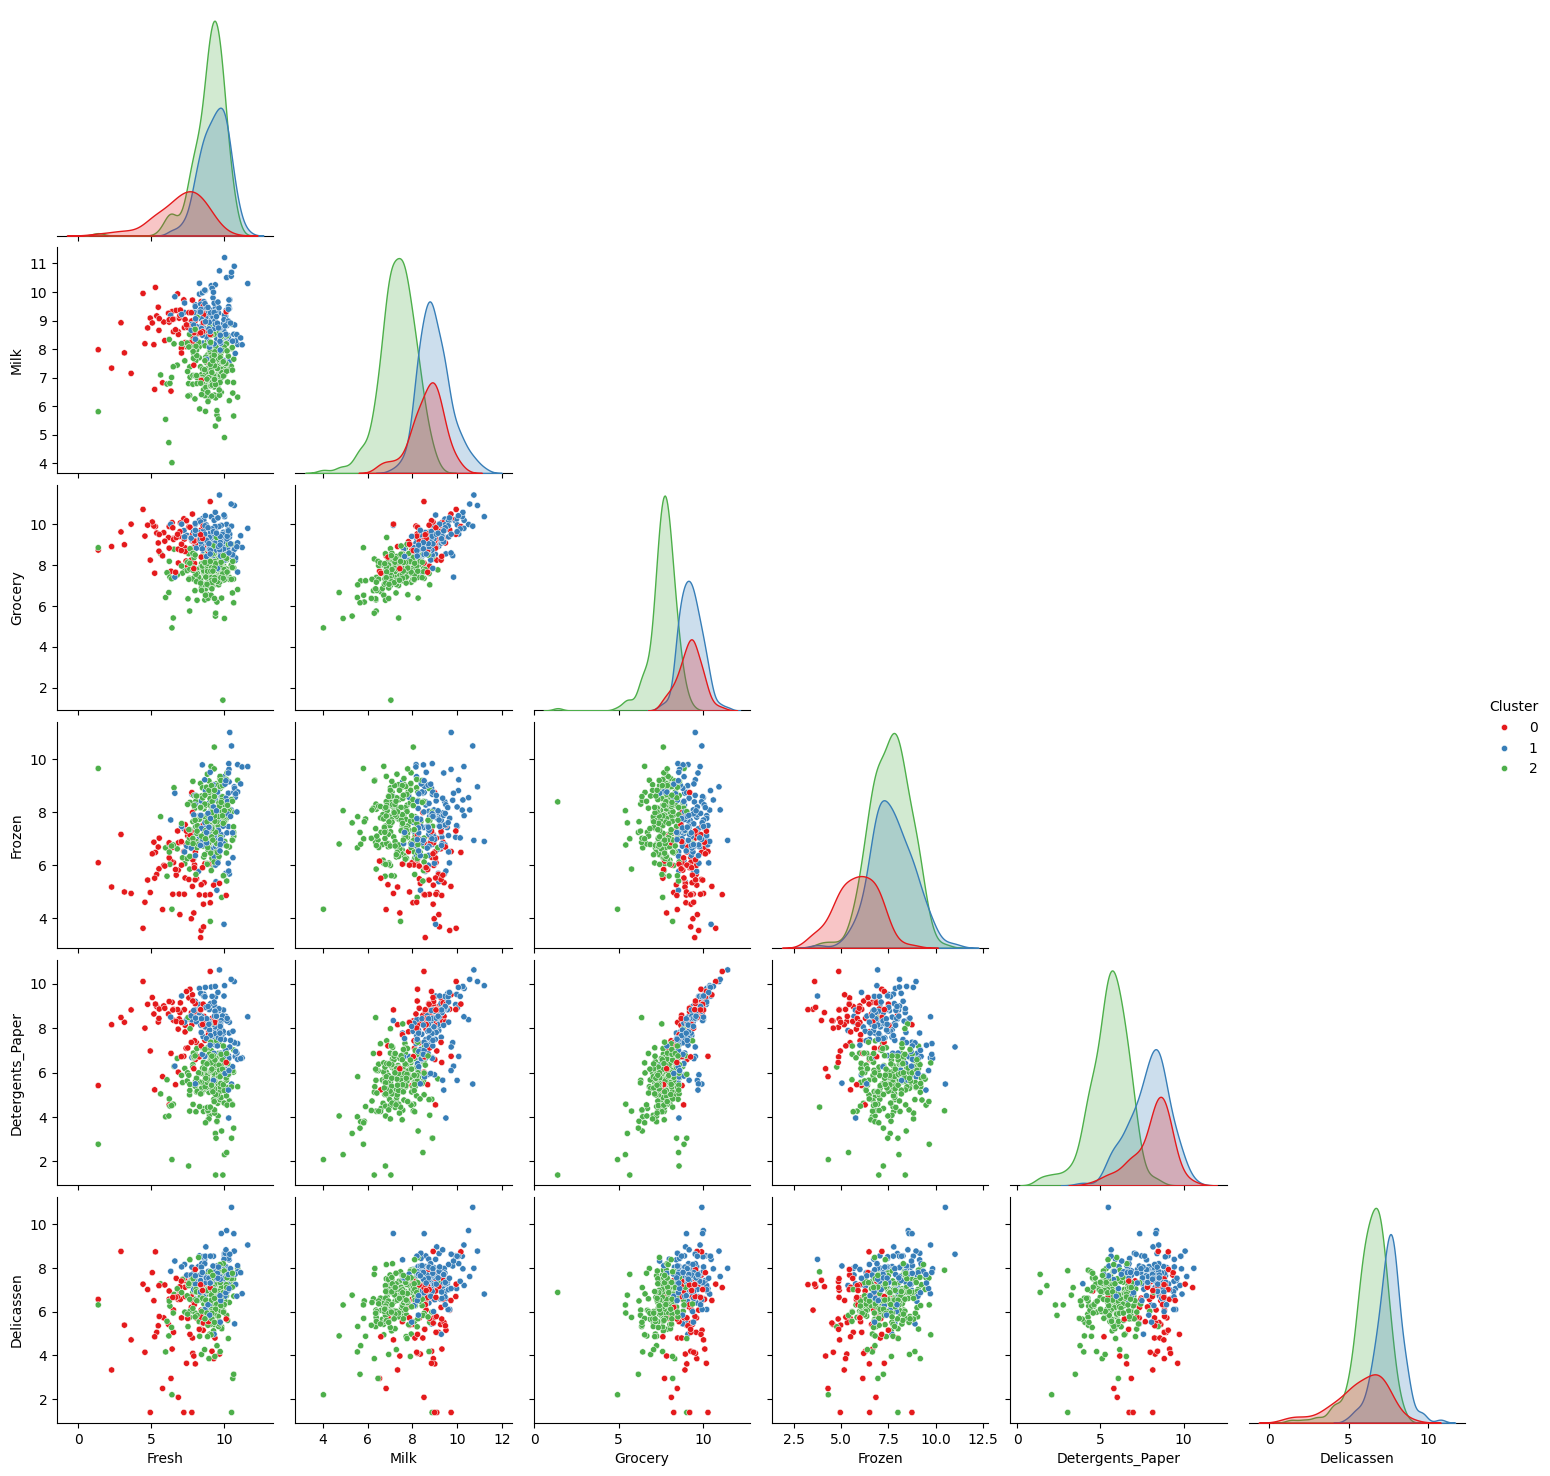

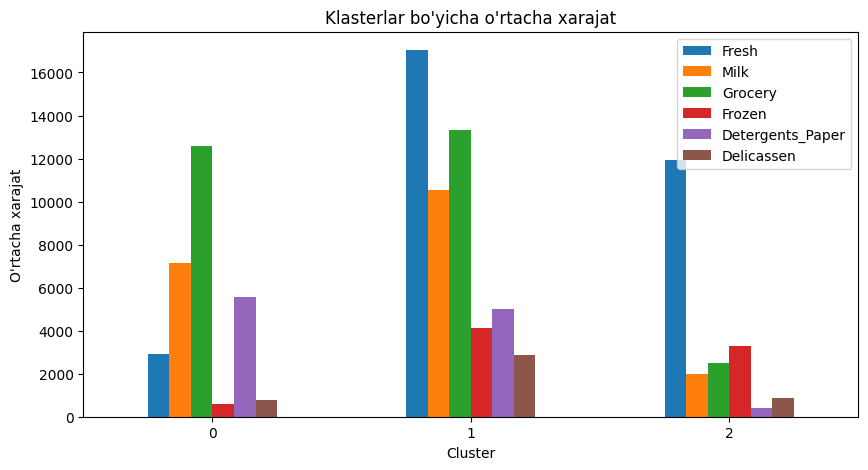

         Fresh   Milk  Grocery  Frozen  Detergents_Paper  Delicassen
Cluster                                                             
0         2899   7136    12570     607              5554         783
1        17043  10560    13334    4133              4987        2847
2        11939   2006     2502    3266               424         891
Channel    1   2
Cluster         
0         32  48
1         56  91
2        210   3


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

df = pd.read_csv("https://raw.githubusercontent.com/alishermutalov/praktikum-datasets/refs/heads/praktikum/Wholesale_customers_data.csv")
cols = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]

# ---------- 1. Ma'lumotlarni tayyorlash ----------
# Channel va Region olib tashlanadi (faqat xarajat ustunlari ishlatiladi)
print(df[cols].skew().round(1).to_dict())
X_log = np.log1p(df[cols])
X = StandardScaler().fit_transform(X_log)

# ---------- 2. K-means ----------
# Klasterlar sonini tanlash (elbow va silhouette)
ks = range(2, 9)
inertia = [KMeans(k, n_init=10, random_state=42).fit(X).inertia_ for k in ks]
sil = [silhouette_score(X, KMeans(k, n_init=10, random_state=42).fit_predict(X)) for k in ks]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ks, inertia, "o-"); ax[0].set_title("Elbow (inertia)"); ax[0].set_xlabel("k")
ax[1].plot(ks, sil, "o-"); ax[1].set_title("Silhouette"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.show()

kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
df["Cluster"] = kmeans.fit_predict(X)
print(df["Cluster"].value_counts().sort_index())

# ---------- 3. Vizualizatsiya ----------
# Pairplot (logarifmlangan qiymatlarda, klasterlar rang bilan)
sns.pairplot(X_log.assign(Cluster=df["Cluster"]), hue="Cluster", palette="Set1", corner=True, plot_kws={"s": 20})
plt.show()

# Har bir segmentning o'rtacha xarajati
means = df.groupby("Cluster")[cols].mean()
means.plot(kind="bar", figsize=(10, 5), rot=0, title="Klasterlar bo'yicha o'rtacha xarajat")
plt.ylabel("O'rtacha xarajat"); plt.show()
print(means.round(0).astype(int))

# Klasterlar mijoz turi (Channel) bilan qanchalik mos (tekshiruv uchun)
print(pd.crosstab(df["Cluster"], df["Channel"]))